# Affinity Predictor

## Imports

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader, Dataset

from models.predictor_model import AffinityPredictor
from helpers import create_model_name

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", DEVICE)

Using: cuda


## Config

In [2]:
PROJECT_ROOT = os.path.abspath("..")

# Inputs, written by prepare_data.ipynb
DATA_DIR = os.path.join(PROJECT_ROOT, "open_task", "data")
DRUG_EMBEDDING_FILE = os.path.join(DATA_DIR, "drug_embedding.npy")
PROTEIN_EMBEDDING_FILE = os.path.join(DATA_DIR, "protein_embedding.npy")
SPLIT_PATTERN = os.path.join(DATA_DIR, "protein-holdout-{holdout}", "{dataset}_{split}.csv")
DRUG_ID_COLUMN = "drug_id"
PROTEIN_ID_COLUMN = "protein_id"
AFFINITY_COLUMN = "affinity"
SPLITS = ("train", "val", "test")

TRAIN = True

DEFAULTS = {
    "hidden_sizes": (512, 256, 256),
    "dropout": 0.1,
    "batch_size": 256,
    "learning_rate": 1e-4,
    "max_epochs": 200,
    "patience": 20,
    "seed": 0,
}

RUNS = [
    {"dataset": "kiba", "holdout": 0.0},
    {"dataset": "kiba", "holdout": 0.1},
    {"dataset": "kiba", "holdout": 0.2},
    {"dataset": "kiba", "holdout": 0.3},
    {"dataset": "kiba", "holdout": 0.5},
    {"dataset": "kiba", "holdout": 0.75},
    {"dataset": "davis", "holdout": 0.0},
    {"dataset": "davis", "holdout": 0.1},
    {"dataset": "davis", "holdout": 0.2},
    {"dataset": "davis", "holdout": 0.3},
    {"dataset": "davis", "holdout": 0.5},
    {"dataset": "davis", "holdout": 0.75}
]

TRAIN_COLOR = "#2a78d6"
VAL_COLOR = "#eb6834"
TEXT_COLOR = "#0b0b0b"
MUTED_COLOR = "#52514e"
GRID_COLOR = "#e5e4e0"

# Outputs
MODEL_DIR = os.path.join(PROJECT_ROOT, "open_task", "models", "saved_models")
MODEL_PATTERN = os.path.join(MODEL_DIR, "predictor_{name}.pt")
FIGURE_DIR = os.path.join(PROJECT_ROOT, "open_task", "figures")
FIGURE_PATTERN = os.path.join(FIGURE_DIR, "training_{name}.png")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

pd.set_option("display.float_format", "{:.4f}".format)


def resolve(run):
    return {**DEFAULTS, **run, "name": create_model_name(run["dataset"], run["holdout"])}


runs = [resolve(run) for run in RUNS]

display(pd.DataFrame(runs).set_index("name"))

,hidden_sizes,dropout,batch_size,learning_rate,max_epochs,patience,seed,dataset,holdout
name,,,,,,,,,
kiba_holdout_0.0,"(512, 256, 256)",0.1000,256,0.0001,200,20,0,kiba,0.0000
kiba_holdout_0.1,"(512, 256, 256)",0.1000,256,0.0001,200,20,0,kiba,0.1000
kiba_holdout_0.2,"(512, 256, 256)",0.1000,256,0.0001,200,20,0,kiba,0.2000
kiba_holdout_0.3,"(512, 256, 256)",0.1000,256,0.0001,200,20,0,kiba,0.3000
kiba_holdout_0.5,"(512, 256, 256)",0.1000,256,0.0001,200,20,0,kiba,0.5000
kiba_holdout_0.75,"(512, 256, 256)",0.1000,256,0.0001,200,20,0,kiba,0.7500
davis_holdout_0.0,"(512, 256, 256)",0.1000,256,0.0001,200,20,0,davis,0.0000
davis_holdout_0.1,"(512, 256, 256)",0.1000,256,0.0001,200,20,0,davis,0.1000
davis_holdout_0.2,"(512, 256, 256)",0.1000,256,0.0001,200,20,0,davis,0.2000


## Embeddings

In [3]:
drug_vectors = torch.from_numpy(np.load(DRUG_EMBEDDING_FILE)).to(DEVICE)
protein_vectors = torch.from_numpy(np.load(PROTEIN_EMBEDDING_FILE)).to(DEVICE)

display(pd.DataFrame(
    [
        {"entity": "drug", "rows": drug_vectors.shape[0], "dim": drug_vectors.shape[1]},
        {"entity": "protein", "rows": protein_vectors.shape[0], "dim": protein_vectors.shape[1]},
    ]
).set_index("entity"))

,rows,dim
entity,,
drug,2127,768
protein,429,320


## Splits

In [4]:
class PairDataset(Dataset):
    def __init__(self, frame):
        self.drug_ids = torch.tensor(frame[DRUG_ID_COLUMN].to_numpy(), dtype=torch.long)
        self.protein_ids = torch.tensor(frame[PROTEIN_ID_COLUMN].to_numpy(), dtype=torch.long)
        self.affinities = torch.tensor(frame[AFFINITY_COLUMN].to_numpy(), dtype=torch.float32)

    def __len__(self):
        return len(self.affinities)

    def __getitem__(self, index):
        return self.drug_ids[index], self.protein_ids[index], self.affinities[index]


def build_loaders(dataset, holdout, batch_size):
    return {
        split: DataLoader(
            PairDataset(pd.read_csv(
                SPLIT_PATTERN.format(dataset=dataset, holdout=holdout, split=split))),
            batch_size=batch_size,
            shuffle=(split == "train"),
        )
        for split in SPLITS
    }


# Runs sharing a dataset, holdout and batch size share one set of loaders
loaders = {}
for settings in runs:
    key = (settings["dataset"], settings["holdout"], settings["batch_size"])
    if key not in loaders:
        loaders[key] = build_loaders(*key)

display(pd.DataFrame(
    [
        {"dataset": dataset, "holdout": holdout, "split": split, "pairs": len(loader.dataset)}
        for (dataset, holdout, _), dataset_loaders in loaders.items()
        for split, loader in dataset_loaders.items()
    ]
).set_index(["dataset", "holdout", "split"]))

pairs
dataset holdout split       
kiba    0.0000  train  82359
                val    17648
                test   17650
        0.1000  train  74013
                val    17648
                test   17650
        0.2000  train  64867
                val    17648
                test   17650
        0.3000  train  57698
                val    17648
                test   17650
        0.5000  train  43502
                val    17648
                test   17650
        0.7500  train  22311
                val    17648
                test   17650
davis   0.0000  train  18040
                val     3865
                test    3867
        0.1000  train  16225
                val     3865
                test    3867
        0.2000  train  14434
                val     3865
                test    3867
        0.3000  train  12640
                val     3865
                test    3867
        0.5000  train   9021
                val     3865
                test    3867
        0.7500  train   4511
                val     3865
                test    3867

## Model

In [5]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total = 0.0

    for drug_ids, protein_ids, affinities in loader:
        drug_ids = drug_ids.to(DEVICE)
        protein_ids = protein_ids.to(DEVICE)
        affinities = affinities.to(DEVICE)

        with torch.set_grad_enabled(train):
            loss = criterion(model(drug_ids, protein_ids), affinities)

        if train:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        total += loss.item() * len(affinities)

    return total / len(loader.dataset)


criterion = nn.MSELoss()

print(AffinityPredictor(drug_vectors, protein_vectors, DEFAULTS["hidden_sizes"], DEFAULTS["dropout"]))

AffinityPredictor(
  (mlp): Sequential(
    (0): Linear(in_features=1088, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=256, out_features=256, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.1, inplace=False)
    (9): Linear(in_features=256, out_features=1, bias=True)
  )
)


## Training

In [6]:
histories = {}
models = {}

for settings in runs:
    name = settings["name"]
    model_file = MODEL_PATTERN.format(name=name)
    run_loaders = loaders[settings["dataset"], settings["holdout"], settings["batch_size"]]

    torch.manual_seed(settings["seed"])
    model = AffinityPredictor(
        drug_vectors, protein_vectors, settings["hidden_sizes"], settings["dropout"]).to(DEVICE)
    models[name] = model

    if TRAIN:
        optimizer = torch.optim.Adam(model.parameters(), lr=settings["learning_rate"])
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, patience=settings["patience"] // 2)

        history = []
        best_val_mse = float("inf")
        best_epoch = 0
        epochs_without_improvement = 0

        print(name)

        for epoch in range(1, settings["max_epochs"] + 1):
            train_mse = run_epoch(model, run_loaders["train"], criterion, optimizer)
            val_mse = run_epoch(model, run_loaders["val"], criterion)
            learning_rate = optimizer.param_groups[0]["lr"]
            scheduler.step(val_mse)
            history.append((epoch, train_mse, val_mse))

            improved = val_mse < best_val_mse
            if improved:
                best_val_mse = val_mse
                best_epoch = epoch
                epochs_without_improvement = 0
                torch.save(model.state_dict(), model_file)
            else:
                epochs_without_improvement += 1

            marker = "Improved" if improved else "No Improvement"
            print(f"Epoch: {epoch:>5} | Train MSE: {train_mse:.4f} | Val MSE: {val_mse:.4f} | LR: {learning_rate:.2e} | {marker}")

            if epochs_without_improvement >= settings["patience"]:
                print(f"no improvement for {settings['patience']} epochs, stopping")
                break

        histories[name] = history
        print(f"best epoch {best_epoch} | val {best_val_mse:.4f} | {os.path.basename(model_file)}\n")

    # Evaluate the best weights, not the last ones
    model.load_state_dict(torch.load(model_file, map_location=DEVICE))

kiba_holdout_0.0
Epoch:     1 | Train MSE: 13.0533 | Val MSE: 0.6776 | LR: 1.00e-04 | Improved
Epoch:     2 | Train MSE: 0.9968 | Val MSE: 0.6092 | LR: 1.00e-04 | Improved
Epoch:     3 | Train MSE: 0.9075 | Val MSE: 0.5748 | LR: 1.00e-04 | Improved
Epoch:     4 | Train MSE: 0.8436 | Val MSE: 0.5540 | LR: 1.00e-04 | Improved
Epoch:     5 | Train MSE: 0.7985 | Val MSE: 0.5106 | LR: 1.00e-04 | Improved
Epoch:     6 | Train MSE: 0.7716 | Val MSE: 0.4833 | LR: 1.00e-04 | Improved
Epoch:     7 | Train MSE: 0.7422 | Val MSE: 0.4620 | LR: 1.00e-04 | Improved
Epoch:     8 | Train MSE: 0.7178 | Val MSE: 0.4552 | LR: 1.00e-04 | Improved
Epoch:     9 | Train MSE: 0.7116 | Val MSE: 0.4392 | LR: 1.00e-04 | Improved
Epoch:    10 | Train MSE: 0.6995 | Val MSE: 0.4270 | LR: 1.00e-04 | Improved
Epoch:    11 | Train MSE: 0.6939 | Val MSE: 0.4331 | LR: 1.00e-04 | No Improvement
Epoch:    12 | Train MSE: 0.6827 | Val MSE: 0.4334 | LR: 1.00e-04 | No Improvement
Epoch:    13 | Train MSE: 0.6738 | Val MSE: 0.

## Curve

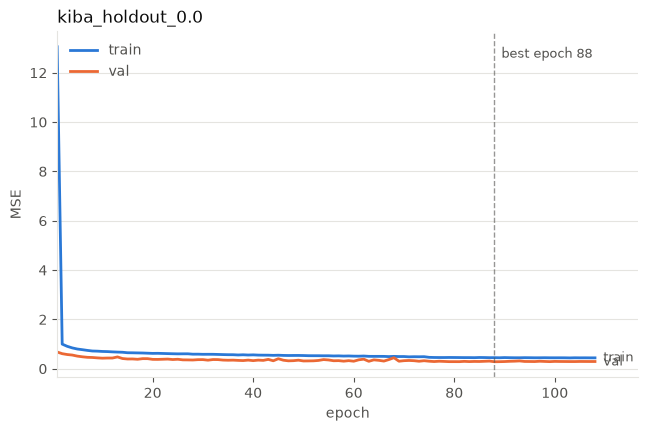

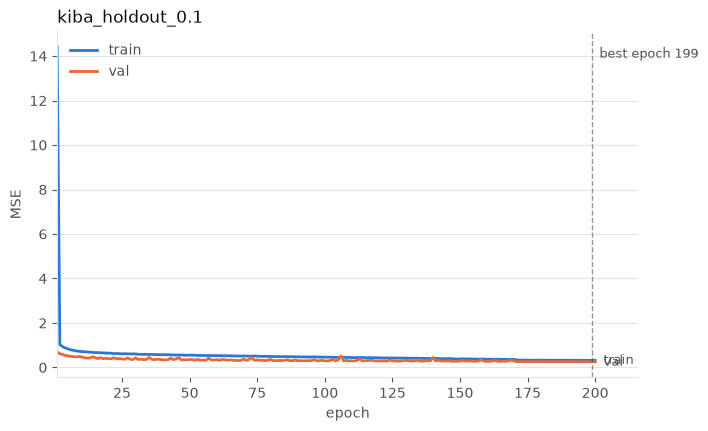

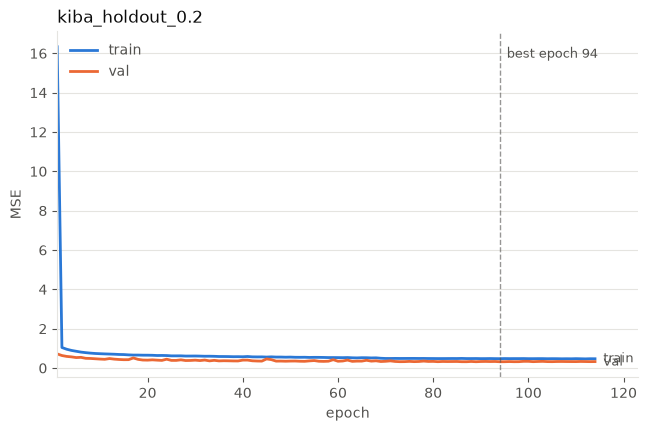

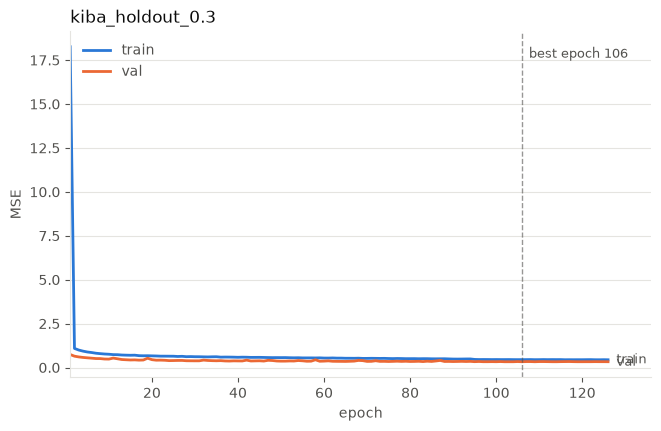

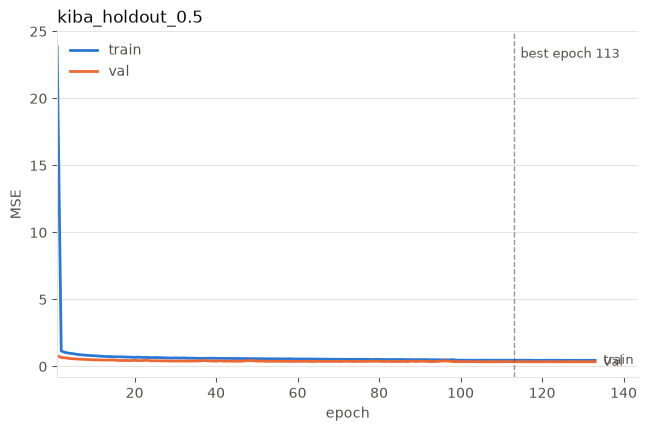

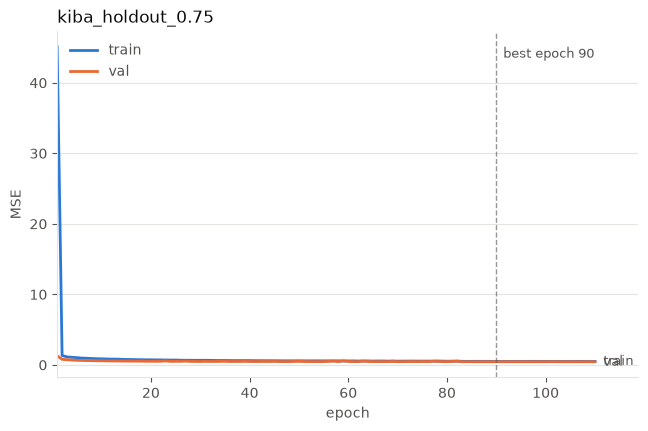

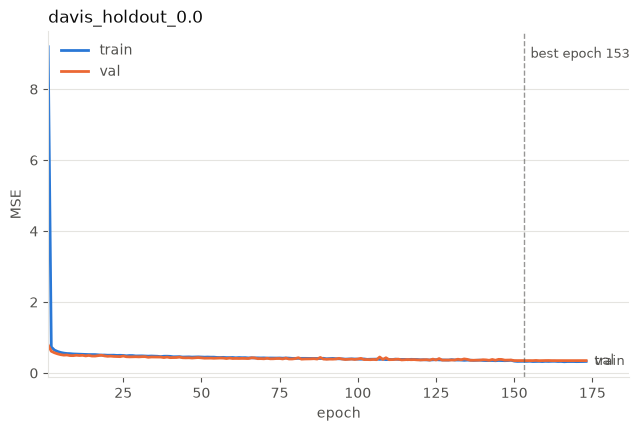

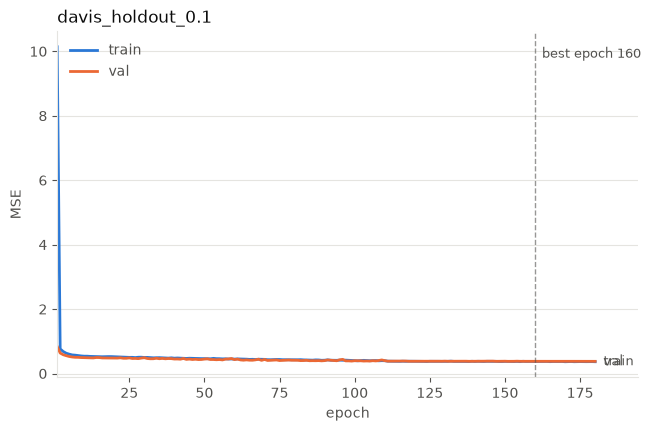

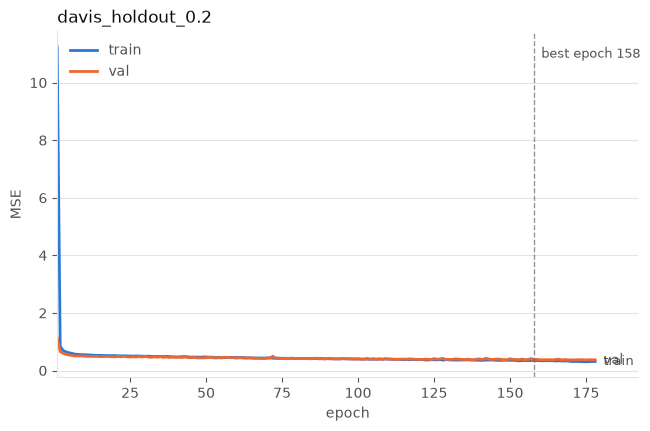

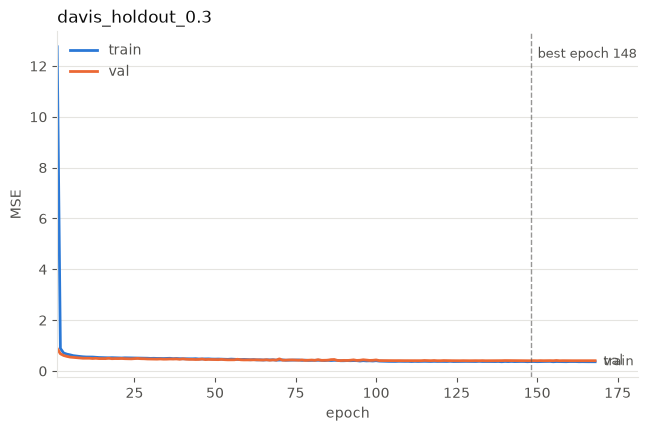

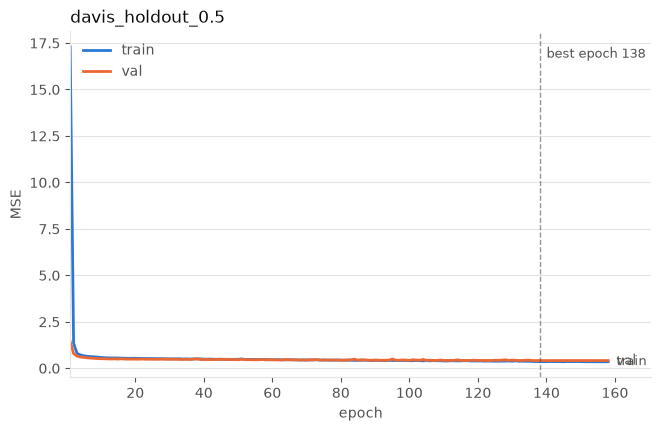

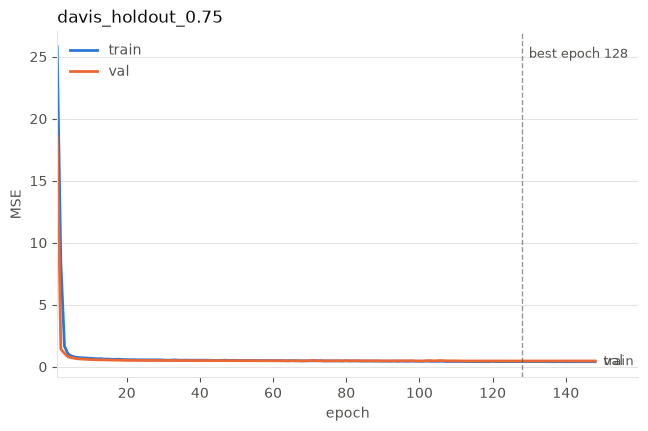

In [7]:
for name, history in histories.items():
    epochs, train_curve, val_curve = zip(*history)
    best_epoch = min(history, key=lambda row: row[2])[0]

    figure, axes = plt.subplots(figsize=(7.5, 4.5))
    axes.plot(epochs, train_curve, color=TRAIN_COLOR, linewidth=2, label="train")
    axes.plot(epochs, val_curve, color=VAL_COLOR, linewidth=2, label="val")

    axes.axvline(best_epoch, color=MUTED_COLOR, linewidth=1, linestyle="--", alpha=0.6)
    axes.annotate(
        f"best epoch {best_epoch}",
        xy=(best_epoch, max(max(train_curve), max(val_curve))),
        xytext=(5, 0),
        textcoords="offset points",
        fontsize=9,
        color=MUTED_COLOR,
        va="top",
    )

    # Direct labels, so the series are not told apart by colour alone
    for label, curve in (("train", train_curve), ("val", val_curve)):
        axes.annotate(
            label,
            xy=(epochs[-1], curve[-1]),
            xytext=(6, 0),
            textcoords="offset points",
            fontsize=9,
            color=MUTED_COLOR,
            va="center",
        )

    # Room on the right for those labels
    axes.set_xlim(epochs[0], epochs[-1] + max(1, len(epochs) * 0.08))

    axes.set_title(name, color=TEXT_COLOR, loc="left")
    axes.set_xlabel("epoch", color=MUTED_COLOR)
    axes.set_ylabel("MSE", color=MUTED_COLOR)
    axes.legend(frameon=False, labelcolor=MUTED_COLOR)
    axes.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
    axes.set_axisbelow(True)
    axes.spines["top"].set_visible(False)
    axes.spines["right"].set_visible(False)
    axes.spines["left"].set_color(GRID_COLOR)
    axes.spines["bottom"].set_color(GRID_COLOR)
    axes.tick_params(colors=MUTED_COLOR)

    figure.savefig(FIGURE_PATTERN.format(name=name), dpi=150, bbox_inches="tight")
    plt.show()

## Evaluation

In [8]:
display(pd.DataFrame(
    [
        {
            "name": settings["name"],
            "split": split,
            "MSE": run_epoch(
                models[settings["name"]],
                loaders[settings["dataset"], settings["holdout"], settings["batch_size"]][split],
                criterion,
            ),
        }
        for settings in runs
        for split in ("val", "test")
    ]
).assign(RMSE=lambda frame: frame["MSE"] ** 0.5).set_index(["name", "split"]))

MSE   RMSE
name               split              
kiba_holdout_0.0   val   0.2822 0.5312
                   test  0.2951 0.5432
kiba_holdout_0.1   val   0.2557 0.5056
                   test  0.2639 0.5137
kiba_holdout_0.2   val   0.3198 0.5655
                   test  0.3296 0.5741
kiba_holdout_0.3   val   0.3288 0.5734
                   test  0.3415 0.5843
kiba_holdout_0.5   val   0.3533 0.5944
                   test  0.3628 0.6024
kiba_holdout_0.75  val   0.4451 0.6671
                   test  0.4585 0.6771
davis_holdout_0.0  val   0.3476 0.5896
                   test  0.3781 0.6149
davis_holdout_0.1  val   0.3768 0.6139
                   test  0.4049 0.6363
davis_holdout_0.2  val   0.3665 0.6054
                   test  0.3897 0.6243
davis_holdout_0.3  val   0.4028 0.6347
                   test  0.4342 0.6589
davis_holdout_0.5  val   0.4145 0.6438
                   test  0.4397 0.6631
davis_holdout_0.75 val   0.4635 0.6808
                   test  0.4791 0.6922